# Week 5: Linear models <span style="font-size: 0.3em;">v20262909b</span>

**Content:**
- Part 1: Linear Regression in 1D
- Part 2: Fitting non-linear data with Linear Regression in 1D
- Part 3: Linear regression on the Wine dataset
- Part 4: Logistic regression (from first principles) on the Wine dataset
- [Assignment 5: Linear models on the Whisky dataset](#my-anchor5)


**Objective:** become familiar with fitting linear regression models in Python.


In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import sklearn.linear_model as lm
import seaborn as sns

# Plotting style
sns.set_style('darkgrid')
sns.set_theme(font_scale=1.)

## Introduction

Regression is widely used in data mining and machine learning for predicting an output (dependent variable) for a data object given its attributes. Regression can be defined as the task of learning a target function that maps a set of attributes onto an output. In other words, regression is a *supervised learning* techniques that generalizes from known examples.

We will initially consider a linear regression problem with the goal of modeling the outputs, $\boldsymbol{y}=\left[y_1, y_2, \dots,  y_N\right]^\top$, based on a single attribute for each of $N$ data objects, $\boldsymbol{X}=\left[x_1, x_2, \dots, x_N\right]^\top$. To do this, we consider the model 
$$
\begin{equation*}
    y_n=w_0+w_1x_n+\epsilon_n,
\end{equation*}
$$
where $\epsilon_n$ is residual noise, $w_0$ a constant offset and $w_1$ the linear coefficient for $x_n$. We can write an equation for the target $y_n$ for each data object as
$$
\begin{aligned}
    y_1&=w_0+w_1x_1+\epsilon_1\\
    y_2&=w_0+w_1x_2+\epsilon_2\\
    &\qquad \qquad \vdots  \\
    y_N&=w_0+w_1x_N+\epsilon_N.\\
\end{aligned}
$$

We can think of the $n$'th equation as a vector product between the fixed true weight vector, $\boldsymbol{w} = \left[ w_0 , w_1 \right]^\top$, and the modified data point, $\tilde{\boldsymbol{x}}_n = \left [ 1, x_n \right ]^\top$. We can collect all modified data points in the matrix $\tilde{\boldsymbol{X}} = \left [ \bf{1} , \boldsymbol{x} \right ]$ where $\mathbf{1} = \left[ 1, 1, \dots , 1 \right]^\top$ is a vector of $N$ ones which allows us to compactly write the equations in matrix-vector form as
$$
\begin{equation*}
    \boldsymbol{y} = \tilde{\boldsymbol{X}} \boldsymbol{w} + \boldsymbol{\epsilon}
\end{equation*}
$$

--------------

## Part 1: Linear Regression in 1D  <a class="anchor" id="part1"></a>
First, we will fit a simple linear regression model to 1-dimensional data generated by the following relation:
$$
    y_n = -0.5 + 0.01 \cdot x_n + \epsilon_n, \quad \epsilon_n \sim \mathcal{N}\left(0, 0.1\right)
$$

Each of the $n$ attribute values $x_n$ should be set to $x_1\!\!=\!0, x_2\!\!=\!1,
x_3\!\!=\!2, \dots, x_N\!\!=\!N-1$ and $\epsilon_n$ describes the observation noise.

**Task 1.1:** Create a function `generate_data` that returns $N$ samples of this 1D dataset in the range $x\in[0,N-1]$. Plot the generated samples and the true noise-free function.
> *Hint*: You can use `np.arange` to make a sequence of integers.

> *Hint*: You can generate random numbers from a univariate Normal distribution using the function `np.random.normal`. 

> *Hint*: It’s a good idea to use `.reshape(-1, 1)` on `X`, `y` and `eps` to get row-vectors. This ensures compatibility with the formulas from the course.

In [ ]:
def generate_data(w=(-0.5, 0.01), N=100, eps_std=0.1, seed=0):
    np.random.seed(seed)

    # YOUR CODE HERE
    raise NotImplementedError()

    return X, y, eps

# Plotting the generated data
N = 100                     # number of data objects
eps_std = 0.1               # observation noise parameter
w = (-0.5, 0.01)            # parameters of the linear relation

# Generate data with your function
X, y, eps = generate_data(eps_std=eps_std, w=w, N=N, seed=0)

# Get the true output values without noise
# YOUR CODE HERE
raise NotImplementedError()

# Plot original data and the model output
f = plt.figure()
plt.plot(X, y, ".", label="Training data")
plt.plot(X, y_true, "-", label=f"Data generator, $w={w}$")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

Generally, in real life problems, we do not know the true coefficients generating the data. Our goal is therefore to *estimate* the coefficients, $w_0$ and $w_1$, from the data observations under the assumption that the data-generating process is linear. For doing so, we minimise the least squares error function, i.e.
$$
\begin{equation*}
    \boldsymbol{w}^\ast = \begin{bmatrix} w_0^\ast \\ w_1^\ast \end{bmatrix} = \arg\min_{w_0, w_1} \sum_{n=1}^N \left(y_n-\left(w_0+w_1x_n\right)\right)^2=\arg\min_{w_0, w_1} \left\|\boldsymbol{y} - \tilde{\boldsymbol{X}} \boldsymbol{w} \right\|_F^2.
\end{equation*}
$$
Solving this optimization problem, the optimal parameter estimate has the closed-form expression
$$
    \boldsymbol{w}^\ast = \left(\tilde{\boldsymbol{X}}^\top \tilde{\boldsymbol{X}}\right)^{-1} \tilde{\boldsymbol{X}}^\top \boldsymbol{y}
$$
Based on the estimated parameters we can predict the value of an unobserved output $y^\ast$ from an observed measurement $x^*$ as
$$
\begin{equation*}
    y_\ast = \left[\begin{array}{c} 1 & x_\ast \end{array} \right] \left[  \begin{array}{c} w^\ast_0 \\ w^\ast_1\end{array} \right] = \boldsymbol{x}_\ast^\top \tilde{\boldsymbol{w}}^\ast
\end{equation*}
$$

**Task 1.2:** Fit a linear model to the data points and plot the estimated model on top of the data and true function.
> *Hint*: First create `X_tilde` by adding to `X` a column of ones. This allows you to compute `w_star`, by using `np.linalg.solve`. Finally, `y_est`is obtained by multiplying `X_tilde`and `w_star`.

> **Optional:** Try using sklearn's `sklearn.linear_model.LinearRegression` as an alternative. Do the two methods agree?

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

# Plotting the generated data along with the true data generator and the estimated model
f = plt.figure()
plt.plot(X, y, ".")
plt.plot(X, y_true, "-")
plt.plot(X, y_est, "-")
plt.xlabel("X")
plt.ylabel("y")
plt.legend(["Training data", f"Data generator, $w={w}$", f"Regression fit (model), w = {np.round(w_star,3)}"])
plt.show()

**Task 1.3:** Explain how the model estimates the parameters, $w_0$ and $w_1$, from the data you have generated.

- *Answer:*

**Task 1.4:** Explain why the estimated parameters are close, but not exactly equal, to the parameters used to generate the data.

- *Answer:*


**Task 1.5:** Go back and play around with the number of data samples, `N`, and the noise variance, `eps_std`. How can you get the estimated model parameters closer to the actual parameters used to generate the data?

<br>

----------

## Part 2: Fitting non-linear data with a linear model - linear Regression in 1D  <a class="anchor" id="part2"></a>

Sometimes there are more complex relationships between the attributes and output. In order to capture more complex relationships we can include attributes that are specified transformations of existing attributes such as $\sqrt{x}$, $\log{(x)}$, $x^2$ and $x^3$. 


We will presently consider the model

\begin{equation*}
y_n = w_0 + \sum_{k=1}^{K} w_k x_n^k + \epsilon_n.
\end{equation*}

You can see this as a generalisation of Part 1, where $K=1$.

The above model can again be written for all $N$ observations simultaneously in terms of vectors and matrices, i.e.

$$
\boldsymbol{y} = \left[\boldsymbol{1}\ \boldsymbol{x}^1\ \boldsymbol{x}^2\ \dots\ \boldsymbol{x}^{K}\right]
\begin{bmatrix}
    w_0 \\
    w_1 \\
    w_2 \\
    \vdots \\
    w_{K}
\end{bmatrix}
+ \boldsymbol{\epsilon}
= \left[\boldsymbol{1}\ \boldsymbol{X}\right] \boldsymbol{w} + \boldsymbol{\epsilon}
$$

where $\boldsymbol{x}^{k}=\left[ x_1^{k}, x_2^{k}, \dots, x_N^{k}\right]^\top$.

<br>

**Task 2.1:** Create a function `generate_data` that returns $N$ samples of this dataset in the range $x\in[-2,2]$. The function should allow you to specify how many $K$ terms to include (squared, cubed, etc.) for generating the data.
> *Hint*: You can use `np.linspace()` to make a sequence of real numbers.
>
> *Hint*: See the function `np.power()` that can raise the content of a vector/matrix to a specified order.

**Task 2.2:** Generate $N=50$ samples with $\boldsymbol{w} = -\begin{bmatrix}-0.9 & -0.9^2 & \dots & -0.9^{K+1}\end{bmatrix}^\top$ for $K=5$. Plot the generated samples and the true function in the range $x\in[-2,2]$ with a higher resolution on the x-axis.  

In [ ]:
def generate_polynomial_data(w, K_data, eps_std, seed=0):
    np.random.seed(seed)

    # YOUR CODE HERE
    raise NotImplementedError()

    return X, y, eps


# Parameters
N = 50                      # no of data objects to train a model
K_data = 5                  # no of terms for data generator
eps_std = 0.5  # noise parameters

# Define the true parameter vector
# YOUR CODE HERE
raise NotImplementedError()

# Generate data with your function
X, y, eps = generate_polynomial_data(w=w_true, K_data=K_data, eps_std=eps_std, seed=0)

# Sampling 1000 points to visualize the true data and model
N_est = 1000
X_est = np.linspace(-2, 2, 1000).reshape(-1, 1)

# Define the true data generator function, y_true (assuming no noise)
# YOUR CODE HERE
raise NotImplementedError()

# Plot original data and the model output
f = plt.figure()
plt.title("Illustration of generated data with noise, and the true data generator")
plt.plot(X, y, ".", label="Training data")
plt.plot(X_est, y_true, "-", label=f"Data generator K={K_data}")
plt.xlabel("X")
plt.ylabel("y")
plt.ylim(-2, 8)
plt.legend()
plt.show()

We now want to fit a model with polynomial terms of order $K_{m}$ to the data generated above. The models output can be formulated as
$$
\begin{equation*}
    y_n = w^\ast_0 + \sum_{k=1}^{K_m} w^\ast_k x_n^k \qquad 
    \text{or} \qquad 
    \boldsymbol{y} = \tilde{\boldsymbol{X}} \boldsymbol{w}^\ast
\end{equation*}
$$
for $N$ observations where $\tilde{\boldsymbol{X}} = \left[\boldsymbol{1}, \boldsymbol{x}, \boldsymbol{x}^2, \dots, \boldsymbol{x}^{K_m} \right]$. Remark the difference between the order of the model, $K_m$, and the order of the data, $K$. This model can fit non-linear trend of the data but is *still linearly dependent on the model weights*. The overall formulation is therefore exactly the same as before for which we know how to compute the coefficients.

<br>


**Task 2.2:** Estimate the model parameters for a model with polynomial order of $K_{m} = 3$. Plot the estimated model on top of the generated data samples and true model.
> *Hint*: Use `X` to create a matrix `X_tilde` and use it for model fitting. 

> *Hint*: Use `X_est`to create a matrix `X_est_tilde` and use it for model prediction. 

> *Hint*: Consider the formula $$w^*=(\tilde{\boldsymbol{X}}^\top\tilde{\boldsymbol{X}})^{-1}\tilde{\boldsymbol{X}}y,$$ which can be found in Chapter 8 of your textbook.



In [ ]:
K_model = 3

# Fit the model with polynomial features up to degree K_model and estimate the outputs as y_est
# YOUR CODE HERE
raise NotImplementedError()

# Plot original data and the model output
f = plt.figure()
plt.plot(X, y, ".", label = "Training data")
plt.plot(X_est, y_true, "-", label = f"Data generator K={K_data}")
plt.plot(X_est, y_est, "-", label = f"Regression fit (model) for K={K_model}")
plt.xlabel("X")
plt.ylabel("y")
plt.ylim(-2, 8)
plt.legend()
plt.show()

print(f"Estimated parameters: {w_star.flatten()}")

**Task 2.3:** Play around with the parameters of the experiment and reflect on how they impact the model fit.
- How well does the model fit the data points? How well does the model fit the true underlying function?

- What happens when fitting a model with more higher order terms, e.g. $K_m=10$ or $K_m=25$? Do you see any potential problems when setting $K_m$ too high?

- Try increasing the number of samples to $N=1000$ while keeping the $K_m=25$. How does this impact the model fit? How did this impact the potential problem?

<br>

----------

## Part 3: Linear regression on the Wine dataset <a class="anchor" id="part3"></a>

We will now take a look at the wine data set and attempt to predict the alcohol content (given in percentage) using linear regression. The linear regression model we consider is

$$
\begin{equation*}
    y_n=w_0+\sum_k w_kx_{n,k}+\epsilon_n,
\end{equation*}
$$
where $y_n$ is the observed alcohol content, $\epsilon_n$ the model residual, $w_k$ the value of the estimated model coefficient for the $k^{th}$ attribute, whereas $x_{n,k}$ denotes the $n^{th}$ observation of the $k^{th}$ attribute. As such, $x_{2,1}$ denotes the second observation of the first attribute (Fixed acidity) and $x_{5,2}$ the fifth observation of the second attribute (Volatile acidity). 

Say we expect volatide acidity (VA) to be around $0-2 \textrm{g}/\textrm{dm}^3$, density (D) to be close to $1 \textrm{g}/\textrm{cm}^3$, and alcohol percentage (AP) to be somewhere between $5-20\% \textrm{vol}$. We can use this knowledge to define wines with VA > 2, D > 1 and AP > 20 as outliers.

**Task 3.1:** Load the Wine dataset in Pandas from the accompanied data-folder and take a look at the data structure. Remove the `"Quality score (0-10)"`-column as well as potential outliers.

> *Hint:* Use `pd.read_csv`, `df.drop()` and `df.head()`

> *Hint:* Pandas allows for logical conditions like `(df['Alcohol'] > 20)` to identify rows with outliers. Combine multiple conditions using the `|` operator (logical OR), and wrap each condition in parentheses. To remove the outliers, consider using the `~` operator to invert the filter.

In [ ]:
# Load the wine dataset in pandas DataFrame
# YOUR CODE HERE
raise NotImplementedError()

print(df.shape)
df.head()

Originally the dataset is used for binary classification on red vs. white wines, which we will also be doing with logistic regression in Part 4. For now we will consider the `Alcohol` content as our target attribute and perform a linear regression using the remaining attributes.

**Task 3.3:** Pick the correct columns of the dataframe, to construct your `X` and `y` matrices containing input attributes and target attributes for the task.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

**Task 3.4:** Fit a linear model of the data points and calculate the residuals. Collect the estimated parameters in a vector (as previously) and plot the estimated model.

> *Hint:* You can use the formula from Task 2.2 to compute $w^*$.

>*Hint:* Which values `y_est` does the model predict for $X$? The residual will be the difference between `y_est`and the true `y`.

In [ ]:
# Fit regression model to the wine dataset
# YOUR CODE HERE
raise NotImplementedError()

# Display scatter plot and histogram of residuals
fig, axs = plt.subplots(2, 1, figsize=(8, 8))
axs[0].scatter(y, y_est, marker='.', alpha=0.5)
# Add x = y line
min_val = min(y.min(), y_est.min())
max_val = max(y.max(), y_est.max())
axs[0].plot([min_val, max_val], [min_val, max_val], 'r-', linewidth=2)

axs[0].set_xlabel("Alcohol content (true)")
axs[0].set_ylabel("Alcohol content (estimated)")
axs[0].set_title("Scatter plot of true vs estimated alcohol content")
axs[1].hist(residual, bins=40, alpha=0.7)
axs[1].set_xlabel("Residuals")
axs[1].set_ylabel("Frequency")
plt.show()

# Estimated parameters, and their attribute names
print("\033[1mEstimated parameters:\033[0;0m")  # Bold text for emphasis
print(f"Intercept: {w_star[0].item():.3f}")
for i, name in enumerate(X.columns):
    print(f"{name}: {w_star[i+1].item():.3f}")


print(f"\nMSE: {np.mean(residual**2):.3f}")

**Task 3.5** Explain what the visualisations tell you about the accuracy of the prediction.


- *Answer:*

**Task 3.6:** Argue from the estimated parameters of the linear regression model that wines with higher alcohol content in general have lower density. Consider verifying it with a small code example: you can take a random wine from the dataset and call it `example`. You then create 100 copies and let the density value vary between `X['Density'].min()`and `X['Density'].max()`. Using your model, you now predict the alcohol value for these new samples.

- *Answer:*

In [ ]:
example = X.iloc[0, :]
# Create a dataframe with many copies of the example
example = pd.DataFrame([example] * 100, columns=X.columns)
# Define a realistic density range
density_vals = np.linspace(X['Density'].min(), X['Density'].max(), 100)
# replace the dummy density attribute with the range
example['Density'] = density_vals.flatten()

# YOUR CODE HERE
raise NotImplementedError()
# Plot the estimated alcohol content as a function of Density
fig = plt.figure()
plt.title("Estimated alcohol content as a function of Density")
plt.plot(density_vals, alc_predict)
plt.xlabel("Density")
plt.ylabel("Alcohol content (estimated)")
plt.show()


**Task 3.7:** Go back to where you defined your data matrix `X`. How does the following affect the performance of your linear regression model (try modifiying you code to do this)?
- Standardization of the input attributes.
- Standardization of the target attribute.
- Adding a new feature that is pure noise.
- Adding a new feature that is very similar to an existing one. E.g. do `X['new-pH'] = X['pH'] + 0.01 * np.random.randn(X.shape[0])`

As we saw in Part 2, specific data attributes can have a non-linear relationship with the output and we need to consider if specific transformations of attributes can capture such non-linear patterns effectively. For determining if there are any obvious transformations, we take a closer look at the wine data set.

**Task 3.8:** Create a figure with subplots that shows each attribute against the alcohol content as scatter plots. Create a similar figure showing each attribute against the model residual.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

**Task 3.9:** Argue what transformations could be useful for making the linear assumption of the regression model more appropriate. Construct a new data matrix `X_tilde` and fit a linear regression model to the transformed wine data. Compute the mean-squared error (MSE) and plot each transformed attribute vs. the residual as scatter plots.

> *Hint*: Feel free to iterate - how low can you get the MSE?

> *Hint*: Plots of attributes versus the model residuals can help reveal if there is structure in the output that can be explained by transformations of the attributes.

> *Hint*: You can use `np.log()`, `np.power()`, `np.multiply()`, etc. on appropriate columns of data matrix.

> *Hint*: The `np.bmat()` function is useful to concatenate matrices and/or vectors.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

---
## Part 4: Logistic regression on the Wine dataset <a class="anchor" id="part4"></a>

Until now we have discussed the most simple linear model based on the squared error cost function. In the generalized linear model, we can also use other loss/cost functions as well as non-linear link functions. 

It can be very useful to limit the possible outputs to the range $(0,1)$ if the outputs we wish to predict are binary. Predicting binary outputs is what we have previously referred to as binary classification and generalized linear models can thus both be used for regression and classification. 


For outputs that are purely binary, $y\in\{0,1\}$, we can use the logistic function, $\sigma(x)=\frac{1}{1+\exp(-x)}$, as the non-linear link function. This function maps the output in the regression analysis to the range $(0,1)$ and ensures that $\sigma(x) = 1 - \sigma(x)$. You can read more about the logistic function [here](https://en.wikipedia.org/wiki/Logistic_function).

Classification with a likelihood function based on the Bernoulli distrbution and logistic link function is called *logistic regression* (for more information [see here](https://en.wikipedia.org/wiki/Logistic_regression)). We will return to the wine data and predict the type of wine using logistic regression. The model we consider is
$$
    p(y_n = 1 \mid \mathbf{x}_n, \mathbf{w})=\sigma\left(w_0+\sum_k w_k x_{n, k}\right)=\sigma\left( \mathbf{w}^T\mathbf{x} \right)
$$
where $p(y_n = 1 \mid \mathbf{x}_n, \mathbf{w})$ is the likelihood of observing and outcome $y=1$ where we encode the of wine with 0 and 1 (Red: $y_n=1$ and White: $y_n=0$) given the model. We will say that a wine is Red with probability $\hat p_n$ and White with probability $1-\hat p_n$. where $\hat p_n=\sigma(w_0+\sum_k w_k x_{n,k})$.

**Task 4.2:** Construct the data matrices `X` and `y` so that they are suitable for solving the binary classification problem.
> *Hint:* All you need to do here add the bias term to the data matrix; everything else is given.

In [ ]:
# Construct X and y for the classification problem, we apply the same filtering as before
df = pd.read_csv('data/wine.csv') # we load the data
df = df[~((df['Volatile acidity'] > 2) | (df['Density'] > 1) | (df['Alcohol'] > 20))] # filter 
X = df.drop(columns=['Color','Quality score (0-10)']) # let's not use the quality score
y = df['Color'].values

# We count the number of types
n_red = (y == "Red").sum()
n_white = (y == "White").sum()
n_total = len(y)
print(f"# Red:   {n_red}")
print(f"# White: {n_white}")
print(f"# Total: {n_total}")

# Encode Red as 0 and White as 1
y = np.array([1 if val == 'Red' else 0 for val in y])
y = y.reshape(-1, 1)

# Std. the dataset (note we will need these values later!)
mu = X.mean(axis=0)                 
sig = X.std(axis=0, ddof=0)       
X_std = (X - mu) / sig       

# Add bias term and save as X_tilde
# YOUR CODE HERE
raise NotImplementedError()

# Print (subset) to check everything look fine
print(f"\nX_tilde = {np.array2string(X_tilde)}")
print(f"\ny = {np.array2string(y)}")

**Task 4.3:** In this task, which is split into multiple parts, we will fit a logistic regression model on `X_tilde`, and predict the labels, `y_est`, and the predicted probabilities of the observation being a white wine, `p_y_one_given_xstar` (white wine is encoded as 1).

To do so, we will write a set of functions which finds the optimal parameter `w_star`thorugh gradient descent and predict the probability of y, $p(y_n\mid \mathbf{x_n}, \mathbf{w})$. 


Recall, the setup is as follows: $
f_n=f({\boldsymbol{x}}_n;\boldsymbol{w})=\boldsymbol{w}^\top {\boldsymbol{x}}_n,
\hat p_n=p(y_n=1 \mid \mathbf{x_n}, \mathbf{w})=\sigma(f_n),$ and $\sigma(z)=\frac{1}{1+e^{-z}}$. 

> *Rationale*: Of course these functions are already implemented in e.g. sklearn and many other places, however we want you do know what these "toolbox" functions actually do, hence we provide the details here. You may wish to get you TA to explain the details but understanding how we get to the gradient is **not** part of the curricilum or exam. 

**Tasks 4.3.1** Complete the function `my_function` that computes and return the function f evaluated at $\mathbf{x}$, i..e, value $f( \boldsymbol{x}; \boldsymbol{w})=\boldsymbol{w}^T\boldsymbol{x}$. The function must be able to compute $f$ for a matrix $\boldsymbol{X}$ and return a vector, `f_val`, as output.

In [ ]:
def my_function(X, w):
    # YOUR CODE HERE
    raise NotImplementedError()
    return f_val

**Task 4.3.2.** Complete the sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$. Save the output in `sigma`. We plot the function for you.

In [ ]:
def link_function_sigmoid(z):
    # YOUR CODE HERE
    raise NotImplementedError()
    return sigma

# We plot how it looks like
zaxis = np.linspace(-5, 5, 1000).reshape(-1, 1)
fig = plt.figure(figsize=(6, 2.5))
plt.plot(zaxis, link_function_sigmoid(zaxis))
plt.xlabel("z")
plt.ylabel(r"$\sigma(z)$")
plt.title("Logistic Link Function")
plt.show()

**Task 4.3.3**  Complete the function `p_y_given_w_and_x` that takes `X`, `w` and `y` as inputs and returns the probabilty of y given the observation.
> * Hint: Use the `link_function_sigmoid` and `my_function` functions from above. Save and return as `p`.

In [ ]:
def p_y_given_w_and_x(w, X, y):
    # YOUR CODE HERE
    raise NotImplementedError()
    return p

**Task 4.3.4** We will implement a loss function that computes the loss for a single data point, effectively the negative log-likelihood of an observation given the model. We have that for an individual observation the loss is the negative log-likelihood, i.e.,

$$e_n(\mathbf{w}) = - log\,p(y_n \mid \mathbf{x}_n, \mathbf{w})$$

Complete the `loss_lr_n` function below to compute $e_n(w)$, Save as `e_n`

> *Hint* You have implemented $p(y \mid \mathbf{x}, \mathbf{w})$ in `p_y_given_w_and_x`

In [ ]:
def loss_lr_n(w,x_n,y_n):
    # YOUR CODE HERE
    raise NotImplementedError()
    return e_n


**Task 4.3.5** Complete the function that computes the loss for all training points $\small E(\mathbf{w}) = - \frac{1}{N} \sum_{n=1}^N log\, p(y_n \mid \mathbf{x}_n , \mathbf{w}) $

  > *Note*: We some times write the loss as the binary cross-entropy $\small  E(\mathbf{w})= -\frac{1}{N}\sum_{n=1}^{N}\left[y_n\log \hat p(y=1\mid \mathbf{x}_n) + (1-y_n)\log 1-\hat p(y=1\mid \mathbf{x}_n))\right].$ We have implemented the function by splitting the computation in two functions to clearly indicate what the likelihood is and what the loss is.

In [ ]:
def loss_lr(w,X,y):   
    # YOUR CODE HERE
    raise NotImplementedError()
    return e

---
***Gradients of the loss function <span style="color:darkred">(optional, skip the first time around and go to the next task)</span>***. We consider the gradient of the loss functio, i.e., how much does the loss change if we change the weights. This is quite math heavy and you are not expected to nessesarily understand everything except the conceptual meaning of what a gradient of a loss funciton is. If we consider the loss (derived from the likelihood) per observation which we need to optimize the the weights $\mathbf{\mathbf{w}}$: $e_n(\mathbf{w})= -\left>[y_n\log \hat p_n + (1-y_n)\log(1-\hat p_n)\right]$ and 
$E(\mathbf{w})=\frac{1}{N}\sum_{i=1}^N e_n(\mathbf{w}).$ where we use the shorthand notation $\hat p_n=p(y_n = 1 \mid \mathbf{x}_n)=\sigma( \mathbf{w}^T \mathbf{x}_n )$.

We exploit the chain rule and get 
$ 
\nabla_\mathbf{w} e_n(\mathbf{w})=\frac{\partial e_n}{\partial \hat p_n}\,
\frac{\partial \hat p_n}{\partial f_n}\,
\nabla_\mathbf{w} f_n.
$ 
The individual terms can be extraced using basic calculus 
$$\small
\frac{\partial e_n}{\partial \hat p_n}
= -\left(y_n\frac{1}{\hat p_n}+(1-y_n)\frac{-1}{1-\hat p_n}\right)
= -\frac{y_n}{\hat p_n}+\frac{1-y_n}{1-\hat p_n}.
\qquad
\frac{\partial \hat p_n}{\partial f_n}
=\sigma'(f_n)
=\sigma(f_n)\big(1-\sigma(f_n)\big)
=\hat p_n(1-\hat p_n).
\qquad
\nabla_\mathbf{w} f_n=\nabla_\mathbf{w} (\mathbf{w}^\top \mathbf{x}_n)=\mathbf{x}_n.
$$

We now get (and simplyfing a bit)
$$
\nabla_\mathbf{w} e_n(\mathbf{w})
=\left(-\frac{y_n}{\hat p_n}+\frac{1-y_n}{1-\hat p_n}\right)\hat p_n(1-\hat p_n)\,\mathbf{x}_n.
\qquad
\left(-\frac{y_n}{\hat p_n}+\frac{1-y_n}{1-\hat p_n}\right)\hat p_n(1-\hat p_n)
= -y_n(1-\hat p_n)+(1-y_n)\hat p_n
= \hat p_n-y_n.
$$

The final per-example gradient becomes
$
\nabla_\mathbf{w} e_n(\mathbf{w})=(\hat p_n-y_n)\mathbf{x}_n
=\Big(\sigma\!\big(f(\mathbf{x}_n;\mathbf{w})\big)-y_n\Big)\mathbf{x}_n.
$
This is important, it tells you how much teh loss change if you change the weights based on a single observation. We are of course interested in how the loss changes across all the observations so we average the gradients accordingly (this is due to rules of differentiation)
$$\small
\nabla_\mathbf{w} E(\mathbf{w})
=\frac{1}{N}\sum_{i=1}^{N}\nabla_\mathbf{w} e_n(\mathbf{w})
=\frac{1}{N}\sum_{i=1}^{N}\Big(\sigma\!\big(f({\mathbf{x}}_n;\mathbf{w})\big)-y_n\Big)\mathbf{x}_n.
$$

Of course we prefer the matrix form as it is more convinient: 
$$\small 
\nabla_\mathbf{w} E(\mathbf{w})=\frac{1}{N}{\mathbf{x}}^\top(\mathbf{\hat p} - \mathbf{y}).
$$
where $\mathbf{y}$ are vectors of length N with the labeles and $\mathbf{\hat p}$ has the $p(y_n=1 \mid \mathbf{x}_n, \mathbf{w})$ values for all $N$ observations. ***This is the equation you need to implement!*** 


---
<br>

**Task 4.3.6** Complete the function below that computes the loss and the gradient of wrt $\mathbf{w}$, i.e. 
$\nabla_\mathbf{w} E(\mathbf{w})=\frac{1}{N}{\boldsymbol{X}}^\top(\mathbf{\hat p} - \mathbf{y})$. Save $\nabla_\mathbf{w} E(\mathbf{w})$ in `g`.

In [ ]:
def loss_and_gradient_lr(w,X,y):        
    N = X.shape[0]
    e = loss_lr(w,X,y)    
    p_hat = p_y_given_w_and_x(w, X, np.ones( (N,1)) ) # to get p hat we compute p(y=1 | w, x) for all the x entries

    # YOUR CODE HERE
    raise NotImplementedError()

    return e, g

**Task 4.3.7** We now need an algorithm that uses the loss function and its gradient to iteratively move toward the best parameter vector $\boldsymbol{w}$. Intuitively, we "walk downhill" on the loss landscape—taking steps in the direction of steepest decrease—until we reach (a) a valley where the loss is minimal, or (b) a point where further improvement becomes negligible.

1. ***Initialize parameters***: Choose an initial guess $\boldsymbol{w}^{(0)}$ (e.g., random values or zeros).
2. ***Choose a learning rate*** Pick a step size $\eta > 0$ (the learning rate).
3. ***Iterate until convergence*** (for $i = 0,1,2,\dots$)  
   - 3.a) Compute the gradient:$\nabla_{\boldsymbol{w}} E\!\left(\boldsymbol{w}^{(i)}\right)$
   - 3.b) Update the parameters by stepping *against* the gradient: $\boldsymbol{w}^{(i+1)}=\boldsymbol{w}^{(i)}-\eta\,\nabla_{\boldsymbol{w}} E\!\left(\boldsymbol{w}^{(i)}\right)$ [this is the code you need to provide]
4. ***Stopping criteria*** Stop when small gradient norm: $\left\|\nabla E\!\left(\boldsymbol{w}^{(i)}\right)\right\| < \varepsilon$, tiny improvement in loss: $\left|E\!\left(\boldsymbol{w}^{(i+1)}\right)-E\!\left(\boldsymbol{w}^{(i)}\right)\right| < \varepsilon$ or maximum number of iterations reached. Here we will use the latter option for simplicity.

Complete the algorithm below by implementing step 3b) (one line).


In [ ]:
def fit_lr(X, y, eta=0.001, n_iter=10000, eta_adaptive=True):
    N, M = X.shape
    w = np.zeros((M, 1)) # init the weight to zero

    print("Iter\tLoss\t\t||grad||\t eta\t\t ||w||")
    print("-" * 60)
    e_prev = np.inf

    for iter in range(n_iter):
        e, gradient = loss_and_gradient_lr(w, X, y)

        # Now update the weights...
        # YOUR CODE HERE
        raise NotImplementedError()
        
        # We implement a simple way to control the learning rate for faster convergence
        if eta_adaptive:
            eta = eta * 0.5 if e > e_prev else eta * 1.005
            e_prev = e
        
        if iter % 100 == 0 or iter == n_iter - 1 or iter == 0:            
            print(f"{iter}\t{e:.6f}\t{np.linalg.norm(gradient):.6f}\t{eta:.6f}\t{np.linalg.norm(w):.6f}")
    return w
    

 > *Note.* Remarkably, this simple principle—minimizing a loss function by following its gradient—is what underpins modern AI and machine learning. Systems such as ChatGPT and Gemini rely on the same core idea, although with far more complex models and loss functions than the simplified setting we consider here.

**Task 4.4**  We will now train/fit the logistic regression model with our simple gradient algorithm and print the weights. You do not have to write code here; just run it and inspect the output (***ask your TA to explain the details***).

In [ ]:
# First we try to fit the logistic regression model
w_star = fit_lr(X_tilde, y)

print(f"\n w*= {np.array2string(w_star.T)}")

**Task 4.5**: Plot the weights as a bar plot and reason about the importance of weights in the final model.

> *Hint*: Remember that we added a collumns of ones to the orginal `X`

In [ ]:
# Visualize the weigths as a bar plot
# YOUR CODE HERE
raise NotImplementedError()

**Task 4.6** Create a function that makes a hard prediction of whether the it is class 0 or 1. It should take the probabilities as input. and return 0 or 1 by thresholding at $p=0.5$. Save the predictions as integers in `y_est`.


In [ ]:
def predict(p, threshold=0.5):
    # YOUR CODE HERE
    raise NotImplementedError()
    return y_est

# Classify wine as White/Red (0/1) and assess probabilities
p_est = p_y_given_w_and_x(w_star, X_tilde, np.ones((X.shape[0],1)))
y_est = predict(p_est)

**Task 4.7:** What is visualized in the plot below? 

- *Answer:*

In [ ]:
plt.figure()
class0_ids = np.nonzero(y == 0)[0].tolist()
plt.plot(class0_ids, p_est[class0_ids], ".y")
class1_ids = np.nonzero(y == 1)[0].tolist()
plt.plot(class1_ids, p_est[class1_ids], ".r")
plt.xlabel("Wine sample")
plt.ylabel("Predicted prob. of class Red (y=1)")
plt.ylim(-0.01, 1.3)
plt.legend(["White", "Red"])

**Task 4.8:** Compute the error rate (aka the misclassificaiton rate), `error_rate`. How does this relate to the accuracy?

In [ ]:
# Evaluate the classifier's misclassification rate over entire training data
# YOUR CODE HERE
raise NotImplementedError()

print("\nOverall misclassification rate: {0:.4f}".format(error_rate))


**Task 4.9:** Use the model to show that the following newly observed wine, would be classified as White wine. Do this by computing and save the probably of $p(y=1 \mid x, w)$ in `p_y_is_one_given_x_star` (i.e. the probability of a red wine).
<div style="font-size:0.9em; columns:3; column-gap:0rem;">
<ul>
  <li>Fixed acidity: 6.9</li>
  <li>Volatile acidity: 1.09</li>
  <li>Citric acid: 0.06</li>
  <li>Residual sugar: 2.1</li>
  <li>Chlorides: 0.0061</li>
  <li>Free sulfur dioxide: 12.0</li>
  <li>Total sulfur dioxide: 31.0</li>
  <li>Density: 0.99</li>
  <li>pH: 3.5</li>
  <li>Sulphates: 0.44</li>
  <li>Alcohol: 12.0</li>
</ul>
</div>

<br>

> *Hint:* Use your function `p_y_given_w_and_x` and recall that we standardized the data!

In [ ]:
# Define the new wine, and evaluate its probability of being a red wine (i.e. y=1).
# YOUR CODE HERE
raise NotImplementedError()

print(f"Probability of given sample being a red wine: {p_y_is_one_given_x_star:.4f}")

**Task 4.10:** Go back to where you defined your data. How does the following affect the performance of your logistic regression model?
- Adding a feature that is pure noise
- Adding a feature that is very similar to an existing one. E.g. do `X['new-pH'] = X['pH'] + 0.01 * np.random.randn(X.shape[0])`
- Removing some of the features
- Not standardization of the input features (Here you would need to run the naiive optimization function for much, much longer and check that you have converged; perhaps use the method in 4.11 to do this)
 

**Task 4.11 <span style="color:darkred">(optional)</span>**: The toolbox sklearn has an convient implementaion of logistic regression, named `sklearn.linear_model.LogisticRegression`. You should use this for actual applications instead of our custom implementation. 

Try to fit the model using `sklearn.linear_model.LogisticRegression`. Do you get the same result as when using our own rather naiive implementation? 

> *Hint:* `LogisticRegression` is tempting to use “as is”, but it performs several steps under the hood (regularization, intercept handling, stopping criteria, solver choices) that can obscure what’s happening when you’re first learning the algorithm. To match the model defined above as closely as possible, use:
>
> `LogisticRegression(max_iter=1000, fit_intercept=False, tol=1e-6, C=np.inf)`
>
> We’ll explain the role of `C` (and its theoretical motivation) later in the course.

In [ ]:
# Fit the logistic regression model using sklearn
# YOUR CODE HERE
raise NotImplementedError()

<a id="my-anchor5"></a>

---

# Assignment 5: 


In this assignment you will use the **Whisky dataset** again. The data in `data/whiskies.txt` (or `data/whiskies.csv`) comes from a number of whisky distilleries, with subjective judgements on flavour characteristics from [this Strathclyde University research project](https://www.mathstat.strath.ac.uk/outreach/nessie/nessie_whisky.html). Each distillery is judged on twelve flavour indicators (e.g. smokiness, sweetness) on a 0–4 scale, i.e. each distillery is a 12-dimensional feature vector.

**The main tasks**

- **5.1** – Fit a **linear regression** model (closed-form OLS) to predict the medicinal rating from the other flavour notes; compute predictions and residuals.
- **5.2** – Build the binary target `y` and design matrix `X_tilde` for Islay classification (using `islay_whiskies`).
- **5.3** – Use/reuse **fit_lr** (gradient descent on cross-entropy, no sklearn).
- **5.4** – Fit the model and compute predicted probabilities `y_est_islay_prob` and predicted class `y_est`.
- **5.5** – Compute and report the **misclassification rate**; optionally plot predicted probabilities by class.
- **5.6** – Print and interpret the fitted weights `w_star` for the Islay classifier.
- **5.7** – Implement a **confusion matrix** function.
- **5.8** – Interpret the results from the confusion matrix.
- **5.9** – Solve a multiple choice question (old exam question) 

In [1]:
# We import everything needed for the assignment part
import matplotlib.pyplot as plt
# Plotting style
import seaborn as sns
sns.set_style('darkgrid')
sns.set_theme(font_scale=1.)

import utils as utils, re
import pandas as pd
import numpy as np

utils.reset_marks()
a,b,c,d = utils.platform_info()
print(f"Platform info: <<<{a}:{b}:{c}:{d}>>>")
with utils.marks(0): # If we get to this point, we will show a checkmark to indicate that everything looks fine so far
    assert(True)

Platform info: <<<['machine-guid:9ae31c38-5105-4f45-9304-7394df884529', 'mac:d4d8537ed9ec', 'node:DESKTOP-RA3GTR4', 'system:Windows', 'release:10', 'machine:AMD64', 'processor:Intel64 Family 6 Model 191 Stepping 2, GenuineIntel']:78848c063262d8ea74dd5b3724b75e45bd5d7a2afb41f2c4b7c6a79eff000f8f:20261021060153:726d8bc51c152f365b5491b44fffaa6e95064232e068cce6e8ca3bbfde9c8d34:python:3.11.16|platform:Windows-10-10.0.26300-SP0|numpy:2.4.6|sklearn:1.9.0|pandas:3.0.5|torch:2.14.0+cpu>>>


<br>

**Assignment 5.0:** Fill in your student ID and your full name in the variables below (and ensure that the cell runs):

In [16]:
student_id = "s254794" 
student_typewritten_signature = "Nicolai Nielsen"

Our first small test is to check that the format of the student id is correct.

In [17]:
# We include such simple tests (without marks) to make sure you are on the right track
with utils.marks(0): 
    assert(re.compile(r"^s\d{6}$").match(student_id))
    assert(len(student_typewritten_signature)>0)

NameError: name 'utils' is not defined

We load the data exactly as last week (you do not have to do anything here):

In [ ]:
df = pd.read_csv("data/whiskies.txt")

# Displaying the dataframe.
display(df.head())

# Removing the names and the location, and saving them in their own variables
distilleries = df["Distillery"]
locations = np.array(df.iloc[:, -2:])
X = df.drop(columns=["RowID", "Distillery", "Postcode", " Latitude", " Longitude"])

islay_whiskies = [
    "Ardbeg",
    "Bowmore",
    "Bruichladdich",
    "Bunnahabhain",
    "Caol Ila",
    "Lagavulin",
    "Laphroaig"
]

,RowID,Distillery,Body,Sweetness,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Fruity,Floral,Postcode,Latitude,Longitude
0,1,Aberfeldy,2,2,2,0,0,2,1,2,2,2,2,2,\tPH15 2EB,286580,749680
1,2,Aberlour,3,3,1,0,0,4,3,2,2,3,3,2,\tAB38 9PJ,326340,842570
2,3,AnCnoc,1,3,2,0,0,2,0,0,2,2,3,2,\tAB5 5LI,352960,839320
3,4,Ardbeg,4,1,4,4,0,0,2,0,1,2,1,0,\tPA42 7EB,141560,646220
4,5,Ardmore,2,2,2,0,0,1,1,1,2,3,1,1,\tAB54 4NH,355350,829140


**Assignment 5.1**: We will use linear regression to predict the medicinal note by completing the below cell. 

- Fit a linear regression model to predict the medicinal rating from the other flavour notes. Although medicinal is ordinal, we will treat it as interval – interpretation should therefore be cautious. Save the parameter you found as `w_star`.
- Use the **closed-form OLS solution** (normal equations): you are given the design matrix $\tilde{\boldsymbol{X}} = [\boldsymbol{1}, \boldsymbol{X}]$, then solve for the weights with $\boldsymbol{w}^* = (\tilde{\boldsymbol{X}}^\top \tilde{\boldsymbol{X}})^{-1} \tilde{\boldsymbol{X}}^\top \boldsymbol{y}$ (e.g. with `np.linalg.solve`). Do not use sklearn for this part.
- Compute the predicted values `y_est` and the residuals `residual` (here: difference between estimated and real value in that order). 

w* (incl bias): [ 1.34116592  0.09921366 -0.19091765  0.41978819  0.45808773 -0.15131162
 -0.02488079 -0.18688494 -0.03821055 -0.10576058 -0.0857774  -0.26732901]

MSE: 0.339


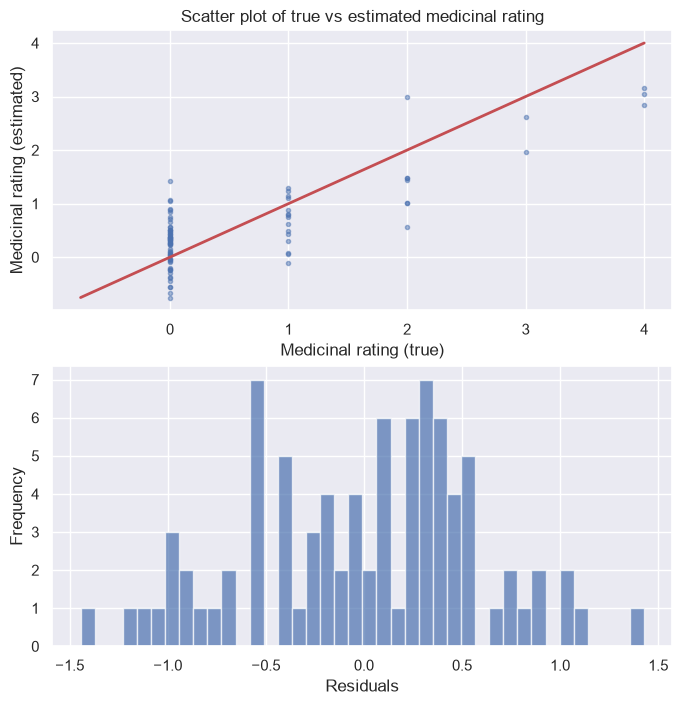

In [ ]:
# Fit regression model to the whiskey dataset
X_m = df.drop(columns=["RowID", "Distillery","Medicinal", "Postcode", " Latitude", " Longitude"])

X_tilde = np.column_stack([np.ones(len(X_m)), X_m])  # Add intercept term
y = df['Medicinal']

# YOUR CODE HERE
w_star = np.linalg.solve(X_tilde.T @ X_tilde, X_tilde.T @ y)
y_est = X_tilde @ w_star
residual = y_est - y

# Display scatter plot and histogram of residuals
fig, axs = plt.subplots(2, 1, figsize=(8, 8))
axs[0].scatter(y, y_est, marker='.', alpha=0.5)
min_val = min(y.min(), y_est.min())
max_val = max(y.max(), y_est.max())
axs[0].plot([min_val, max_val], [min_val, max_val], 'r-', linewidth=2)
axs[0].set_xlabel("Medicinal rating (true)")
axs[0].set_ylabel("Medicinal rating (estimated)")
axs[0].set_title("Scatter plot of true vs estimated medicinal rating")
axs[1].hist(residual, bins=40, alpha=0.7)
axs[1].set_xlabel("Residuals")
axs[1].set_ylabel("Frequency")

# Print estimated parameters
print(f"w* (incl bias): {np.array2string(w_star)}")
print(f"\nMSE: {np.mean(residual**2):.3f}")

In [ ]:
# Test for Assignment 5.1 (OLS and predictions)
with utils.marks(1):
    assert w_star.shape[0] == X_tilde.shape[1], "w_star should have one entry per column of X_tilde"
    assert len(y_est) == len(y), "y_est should have same length as y"
    assert len(residual) == len(y), "residual should have same length as y"
    MSE = np.mean(residual**2)
    assert np.isfinite(MSE) and MSE >= 0, "MSE should be finite and non-negative"
    assert utils.check_scalar(float(MSE), "0x4fa361b")

**Assignment 5.2:** Look at the scatter plot of true vs estimated medicinal rating and the histogram of residuals. In a short paragraph, comment on how well the linear model fits the data and what the residuals tell you (e.g. constant variance, outliers, possible non-linearity). 

- *Answer (max 200 words)*

A linear regression might not be a great fit for this problem. It has an MSE of 0.34, and if we take the square root of that, it tells us our predictions are roughly 0.6 off on the 0 to 4 scale.

From the scatter plot we can see that higher values are estimated lower than their true value. For instance, whiskies with a true score of 4 are estimated to be around 3. Whiskies with a score of 0 are on average estimated slightly too high. 

The residuals don't show any big outliers, since all errors are between about -1.4 and 1.4.

In [ ]:
# A manual test to be assessed by the teaching assistants (not auto-graded)
with utils.marks(1, auto=False, visible=False):
    print("Manual test")

**Assignment 5.3 (Logistic – data):** Using the `islay_whiskies` list from the data-loading cell, construct the binary target vector `y` (1 if the distillery is in that list, 0 otherwise) and the design matrix `X_tilde` (flavour columns plus intercept column of ones). Do not use sklearn.


In [ ]:
# Assignment 5.3: Build y and X_tilde for Islay classification
y = np.array([1 if d in islay_whiskies else 0 for d in distilleries], dtype=float).reshape(-1, 1)

# YOUR CODE HERE
X_tilde = np.column_stack([np.ones(len(X)), X])
print(X_tilde)


NameError: name 'np' is not defined

In [ ]:
# Test for Assignment 5.3 (y, X_tilde)
with utils.marks(1):
    assert utils.check_hash(y, ((86, 1), 145.32452211976985))
    assert utils.check_hash(X_tilde, ((86, 13), 847437.3461418484))

**Assignment 5.4 (Logistic – fit and predict):** 

- Find the weights in the logistic regression model 
     > *Hint*: Reimplement, copy, or even better simply reuse the `fit_lr` function from **Task 4.3.7** to find the weights in a logistic regression model. ***The tests below are made with `n_iter=20000` and otherwise default settings to `fit_lr`.***
     
     > *Hint*: If you use other built-in functions, the test will likely fail, but you will get full marks if done correctly (however be careful with the parameters to these functions!)
     >
- Compute the probability of each whiskey being from Islay in `y_est_islay_prob` and the predicted class in `y_est`.
    > *Hint*: You can use the `p_y_given_w_and_x` and `predict` from Task 4.3 and 4.6, respectively.

In [ ]:
# Assignment 5.4: Fit model and compute y_est_islay_prob, y_est
# YOUR CODE HERE

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def p_y_given_w_and_x(w, X, y):
    p_y_is_one_given_x = sigmoid(X @ w)
    p = y*p_y_is_one_given_x + (1-y)*(1-p_y_is_one_given_x)
    return p

def loss_lr(w, X, y):
    es = -np.log(p_y_given_w_and_x(w, X, y))
    e = np.sum(es) / X.shape[0]
    return e

def loss_and_gradient_lr(w, X, y):
    N = X.shape[0]
    e = loss_lr(w, X, y)
    p_hat = p_y_given_w_and_x(w, X, np.ones((N, 1)))  # p(y=1 | w, x) for all the x entries
    g = (1/N) * X.T @ (p_hat - y)
    return e, g

def fit_lr(X, y, eta=0.001, n_iter=10000, eta_adaptive=True):
    N, M = X.shape
    w = np.zeros((M, 1))

    print("Iter\tLoss\t\t||grad||\t eta\t\t ||w||")
    print("-" * 60)
    e_prev = np.inf

    for iter in range(n_iter):
        e, gradient = loss_and_gradient_lr(w, X, y)

        # Now update the weights...
        w -= eta * gradient

        # We implement a simple way to control the learning rate for faster convergence
        if eta_adaptive:
            eta = eta * 0.5 if e > e_prev else eta * 1.005
            e_prev = e

        if iter % 100 == 0 or iter == n_iter - 1 or iter == 0:
            print(f"{iter}\t{e:.6f}\t{np.linalg.norm(gradient):.6f}\t{eta:.6f}\t{np.linalg.norm(w):.6f}")
    return w

w_star = fit_lr(X_tilde, y, n_iter=20000)
y_est_islay_prob = p_y_given_w_and_x(w_star, X_tilde, np.ones((X_tilde.shape[0], 1)))
y_est = (y_est_islay_prob >= 0.5).astype(int)


NameError: name 'X_tilde' is not defined

In [ ]:
# Test for Assignment 5.4 (y_est_islay_prob, y_est)
with utils.marks(1):
    assert utils.check_hash(y_est_islay_prob, ((86, 1), 145.49994993914572))
    assert utils.check_hash(y_est, ((86, 1), 145.32452211976985))


NameError: name 'utils' is not defined

**Assignment 5.5 (Logistic – evaluation):** Compute and report the misclassification rate for your Islay classifier (store in `misclass_rate`). Optionally plot predicted probabilities by true class (Islay vs not Islay).


In [ ]:
# Assignment 5.5: Misclassification rate and optional plot
# YOUR CODE HERE
misclass_rate = 

print("\nOverall misclassification rate: {0:.4f}".format(misclass_rate))
f = plt.figure()
class0_ids = np.nonzero(y == 0)[0].tolist()
plt.plot(class0_ids, y_est_islay_prob[class0_ids], ".b")
class1_ids = np.nonzero(y == 1)[0].tolist()
plt.plot(class1_ids, y_est_islay_prob[class1_ids], ".r")
plt.xlabel("Data object (whisky sample)")
plt.ylabel("Predicted prob. of Islay origin")
plt.ylim(-0.01, 1.1)
plt.legend(["not from Islay", "Islay"])


In [ ]:
# Test for Assignment 5.5 (misclass_rate)
with utils.marks(1):
    assert 0 <= misclass_rate <= 1, "misclass_rate should be in [0,1]"
    assert utils.check_scalar(float(misclass_rate), "0x75c2e82a")

**Assignment 5.6:** We print the parameters in `w_star`. What does it tell you about Islay whiskies?
 > *Hint*: It might look trivial, but a complete answer would consider the function, the current bias and weights, the sigmoid’s behavior, and the fact that the input features were neither centered nor standardized which is important when interpreting the weights.

In [ ]:
# Assignment 5.6: Print and interpret w_star for the Islay classifier (you do not need to code anything)
print("\033[1mEstimated parameters:\033[0;0m") 
print(f"Weights (including bias term):\n {np.array2string(w_star)}")


- *Answer (max 300 words; you can include latex or images of handwritten equations if needed)*:

YOUR ANSWER HERE

In [ ]:
# A manual test to be assessed by the teaching assistants (not auto-graded)
with utils.marks(3, auto=False, visible=False):
    print("Manual test")

**Assignment 5.7:** Complete a function `confmat(actual, predicted)` that takes the true labels and predicted labels (as 1D arrays or column vectors of 0s and 1s) and returns a 2×2 confusion matrix (e.g. `confmat[i,j]` = count where actual class is `i` and predicted is `j`). Then create the confusion matrix for your Islay classifier.
  > *Hint*: [A quick overview of confusion matrix ](https://en.wikipedia.org/wiki/Confusion_matrix)

In [ ]:
# Confusion matrix
def confmat(actual, predicted):   
    # initialize the confusion matrix
    confmat = np.zeros((2, 2), dtype=int)

    # Loop across the different combinations of actual / predicted classes
    for i in range(2):
        for j in range(2):

           # Count the number of instances in each combination of actual / predicted classes
           # YOUR CODE HERE
           raise NotImplementedError()

    return confmat

# We print/plot the confusion matrix for you
accuracy = np.mean(y_est == y)
print("Confusion matrix:")
print(confmat(y, y_est))
cm = confmat(y, y_est)
# Plot the confusion matrix
fig = plt.figure(figsize=(8, 6))
ax = sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", cbar=True,
    xticklabels=["Not Islay", "Islay"],
    yticklabels=["Not Islay", "Islay"]
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Confusion matrix (Accuracy: {0}%)".format(accuracy))
plt.grid(False)
plt.show()

In [ ]:
# Test for Assignment 5.7 (confusion matrix)
with utils.marks(2):
    assert callable(confmat), "confmat should be a function"
    assert cm.shape == (2, 2), "Confusion matrix should be 2x2"
    assert np.issubdtype(cm.dtype, np.integer), "Confusion matrix should contain integers"
    assert np.sum(cm) == len(y), "Sum of confusion matrix should equal number of samples"
    assert utils.check_hash(cm, ((2, 2), 242.3636973763941))

**Assignment 5.8:** What does the confusion matrix tell us about the classifier? 

- *Answer (max 100 words):*

YOUR ANSWER HERE

In [ ]:
# A manual test to be assessed by the teaching assistants (not auto-graded)
with utils.marks(1, auto=False, visible=False):
    print("Manual test")

**Assignment 5.9:** Provide a solution for the following question (an example of an exam question in a recent no aids exam), and explain your answer in detail. 

Which one of the statements about logistic regression is *correct*?

>
>
>  **A.** The logistic sigmoid function maps from a probability to a continuous value in $]-\infty,\infty[$.  
>
>   **B.** Logistic regression can be used to construct classifiers with nonlinear decision boundaries by considering nonlinear transformations of the inputs.  
>
>   **C.** Logistic regression minimizes the mean squared error between predicted probabilities and labels.
>
>   **D.** The optimal weights for a logistic regression classifier can be always computed by $\boldsymbol{w}^* = (\tilde{\boldsymbol{X}}^\top \tilde{\boldsymbol{X}})^{-1} \tilde{\boldsymbol{X}}^\top\boldsymbol{y}$. 
>
>   **E.** Don't know.
>
>

- *Answer (max 200 words)*:

YOUR ANSWER HERE

In [ ]:
# A manual test to be assessed by the teaching assistants (not auto-graded)
with utils.marks(1, auto=False, visible=False):
    print("Manual test")

<br>

**Assignment 5.10:** Declaration on the use of AI for solving this assignment (mandatory)

Answer by replacing *[your answer here]* with your response.
1. *I abide by [DTU's code of honour](https://student.dtu.dk/en/exam/exam-cheating/dtu-code-of-honour) and take full responsibility for the content of this submission (yes / no)*: 
    - [your answer here] 
2. *To what extent did you use generative AI to solve this assignment (0-100%)*:
    - [your answer here] 
3. *What was the primary use of generative AI, if any (writing / coding / other)*: 
    - [your answer here] 
4. *I feel I understand the key techniques/algorithms/methods/coding elements used in this exercise such that I can apply it in a **no aids** exam (yes/no)*: 
    - [your answer here] 

**Assignment 5.11:** To submit this notebook, upload both teh HTML adn ipynb notebook. Make sure you have run everything in the **Assignment**-part, and convert this notebook to an HTML file.

> *Hint:* Open the **command palette** in Visual Studio Code, by pressing `Cmd + Shift + P` on Mac or `Ctrl + Shift + P` on Windows. 

> *Hint:* Search for `Jupyter: Export to HTML` and save the HTML file. 

> *Hint:* If you are running the notebook in the browser via the Jupyter interface, go to `File`, then `Save` and choose `Save and Export Notebook` as and select HTML.

**<h4>Summary of the points (only valid after rerunning the Assignment-part from scratch)</h4>**

In [ ]:
utils.marks_summary()